# 5장 · 어텐션의 직관 — '어디에 집중할까' 👀

웹 챕터 **"어텐션의 직관"** 과 짝을 이루는 실습입니다.
웹 실험실에서 점수를 드래그했다면, 여기서는 **집중도(소프트맥스)** 와 **가중 평균**을 직접 계산합니다.
(점수를 계산하는 Q·K·V 는 다음 챕터 ch6)

준비물: `pip install -r requirements.txt`

> 🤖 **AI 튜터**: 아래 셀을 실행하면 웹앱처럼 화면 오른쪽 아래에 🤖 버튼이 생깁니다.
> 버튼을 누르면 채팅창이 열리고, 어디를 스크롤해도 그 자리에 떠 있어요. 막히면 언제든 질문하세요.
> (로컬 Ollama 필요. 꺼져 있으면 켜는 방법이 안내되고, 튜터 없이도 학습에는 지장 없습니다.)

In [ ]:
# 🤖 AI 튜터 — 실행하면 오른쪽 아래에 🤖 버튼이 떠요
from tutor import chat

chat('ch5')

## 1. 문장과 단어 벡터

"강아지가 공을 물었다"의 각 단어에 붙인 아주 단순한 2D 의미 벡터입니다. (웹 실험실과 같은 값)

In [1]:
import numpy as np

WORDS = ['강아지가', '공을', '물었다']
VEC = np.array([[1.0, 0.0],   # 강아지가
                [0.0, 1.0],   # 공을
                [0.8, 0.8]])  # 물었다

def softmax(z):
    z = np.asarray(z, float); z = z - z.max()
    e = np.exp(z); return e / e.sum()

## 2. 집중도 → 가중 평균

질문 단어 **'물었다'** 가 각 단어를 얼마나 참고할지 점수를 주고,
소프트맥스로 **합 1의 집중도**를 만든 뒤, 단어 벡터를 그만큼 섞습니다(가중 평균).
$$\text{문맥} = \sum_i w_i\, v_i, \quad w = \text{softmax}(\text{점수})$$

In [2]:
scores = np.array([2.2, 2.0, 0.5])   # '물었다' 기준 관련성 점수
weights = softmax(scores)
context = weights @ VEC              # 가중 평균: Σ w_i * v_i

for w, wt in zip(WORDS, weights):
    print(f'{w}: 집중도 {wt*100:4.1f}%')
print('집중도 합:', round(weights.sum(), 6))
print('섞인 문맥 벡터(가중 평균):', np.round(context, 2))
print('가장 집중한 단어 →', WORDS[int(np.argmax(weights))])

강아지가: 집중도 50.0%
공을: 집중도 40.9%
물었다: 집중도  9.1%
집중도 합: 1.0
섞인 문맥 벡터(가중 평균): [0.57 0.48]
가장 집중한 단어 → 강아지가


## 3. 문장 전체의 어텐션 (셀프 어텐션 맛보기)

모든 단어가 질문 단어가 되어 서로를 참고하면, 집중도 표(어텐션 행렬)가 만들어집니다.
여기선 점수를 손으로 정했습니다(진짜 계산은 ch6 Q·K·V).

In [3]:
# 행 = 질문 단어, 열 = 참고 대상 단어
score_matrix = np.array([
    [2.5, 0.5, 1.0],   # 강아지가 기준
    [0.5, 2.5, 1.0],   # 공을 기준
    [2.2, 2.0, 0.5],   # 물었다 기준
])
attn = np.apply_along_axis(softmax, 1, score_matrix)   # 행마다 소프트맥스

print('어텐션 집중도 행렬 (행=질문, 열=참고):')
print('           ' + '  '.join(f'{w:>5}' for w in WORDS))
for i, w in enumerate(WORDS):
    row = '  '.join(f'{p:5.2f}' for p in attn[i])
    print(f'{w:>7} :  {row}')
print('각 행의 합:', np.round(attn.sum(axis=1), 3))   # 모두 1

어텐션 집중도 행렬 (행=질문, 열=참고):
            강아지가     공을    물었다
   강아지가 :   0.74   0.10   0.16
     공을 :   0.10   0.74   0.16
    물었다 :   0.50   0.41   0.09
각 행의 합: [1. 1. 1.]


## 4. 어텐션 행렬 히트맵

밝을수록 더 많이 참고. 각 단어가 어디에 집중하는지 한눈에 보입니다.

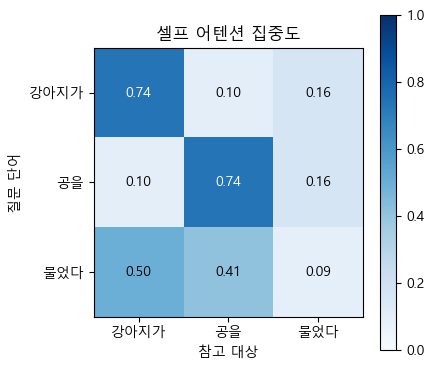

In [4]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(4.5, 4))
plt.imshow(attn, cmap='Blues', vmin=0, vmax=1)
plt.xticks(range(3), WORDS); plt.yticks(range(3), WORDS)
plt.xlabel('참고 대상'); plt.ylabel('질문 단어')
for i in range(3):
    for j in range(3):
        plt.text(j, i, f'{attn[i,j]:.2f}', ha='center', va='center',
                 color='white' if attn[i,j] > 0.5 else 'black')
plt.title('셀프 어텐션 집중도'); plt.colorbar(); plt.tight_layout(); plt.show()

## 5. 직접 해보기 ✏️

집중도 `[0.5, 0.3, 0.2]` 와 값 `[10, 20, 30]` 의 가중 평균을 구하세요. (웹 StepQuiz 와 같은 문제)

In [5]:
w = np.array([0.5, 0.3, 0.2])
vals = np.array([10, 20, 30])
avg = w @ vals
print('가중 평균:', avg)

assert abs(avg - 17) < 1e-9, '각 값 × 집중도 를 더하세요!'
assert abs(w.sum() - 1) < 1e-9, '집중도의 합은 1이어야 합니다!'
print('✅ 0.5·10 + 0.3·20 + 0.2·30 = 17')

가중 평균: 17.0
✅ 0.5·10 + 0.3·20 + 0.2·30 = 17


---
**"집중도(합 1)로 문맥을 가중 평균"**, 이게 어텐션의 핵심입니다.
그런데 그 '점수'는 대체 어떻게 계산할까요? 다음 챕터(ch6)에서 **Q·K·V**(질문·열쇠·값)로 파고듭니다. 🔑